# Proje 1: Sınıflandırma (Classification) - Ağ Trafiği Saldırı Tespiti
## CIC-IDS2017 Veri Seti | CRISP-DM Metodolojisi

---

## 1. Business Understanding (İş Anlayışı)

**Problem:** Ağ trafiği kayıtlarını analiz ederek trafiğin normal mi yoksa bir siber saldırı (DoS/DDoS, Port Scan, Brute Force vb.) mı olduğunu tahmin etmek.

**Amaç:** Farklı sınıflandırma modelleri (Decision Tree, Random Forest ve Logistic Regression) geliştirerek bunların ağ saldırılarını tespit etmedeki performanslarını (Accuracy ve F1-Score) karşılaştırmak.

**Veri Seti:** CIC-IDS2017 – 8 adet CSV dosyası halinde, toplamda yaklaşık 2.8 milyon satır ve 79 özellik içerir. Veri setinin tamamı kullanılacaktır.

**KNIME Uyumluluğu:** KNIME üzerindeki **Random Forest Learner** node'u ile birebir uyumlu bir yapı kullanılmıştır.

## 2. Data Understanding (Veriyi Anlama)

Bu bölümde veri dosyalarını yükleyip birleştiriyoruz, sınıfların dağılımını sadeleştiriyoruz ve eksik/hatalı değerleri temizliyoruz.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
%matplotlib inline

# Sınıfları sadeleştirme
def group_labels(label):
    label = str(label).upper().strip()
    if 'BENIGN' in label:
        return 'NORMAL'
    elif 'DDOS' in label or 'DOS' in label:
        return 'DOS/DDOS'
    elif 'PORT' in label:
        return 'PORT_SCAN'
    elif 'BRUTE' in label:
        return 'BRUTE_FORCE'
    else:
        return 'WEB_ATTACK'

# Tüm veri dosyalarını yükle ve birleştir
dosyalar = [
    '../Data/proje_1/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv',
    '../Data/proje_1/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv',
    '../Data/proje_1/Friday-WorkingHours-Morning.pcap_ISCX.csv',
    '../Data/proje_1/Monday-WorkingHours.pcap_ISCX.csv',
    '../Data/proje_1/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv',
    '../Data/proje_1/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv',
    '../Data/proje_1/Tuesday-WorkingHours.pcap_ISCX.csv',
    '../Data/proje_1/Wednesday-workingHours.pcap_ISCX.csv'
]

dfs = []
for dosya in dosyalar:
    print(f'Yükleniyor: {dosya.split("/")[-1]}...')
    df_temp = pd.read_csv(dosya, encoding='latin1')
    df_temp.columns = df_temp.columns.str.strip()
    df_temp['Label_Group'] = df_temp['Label'].apply(group_labels)
    df_temp.drop(columns=['Label'], inplace=True)
    
    for col in df_temp.columns:
        if col != 'Label_Group':
            df_temp[col] = pd.to_numeric(df_temp[col], errors='coerce')
            df_temp[col] = df_temp[col].astype(np.float32).replace([np.inf, -np.inf], np.nan)
            
    df_temp.dropna(inplace=True)
    dfs.append(df_temp)

data = pd.concat(dfs, ignore_index=True)
data.dropna(inplace=True)
print(f'Toplam Veri Boyutu: {data.shape[0]} satır, {data.shape[1]} sütun')
# Devasa veride RAM yetersizliği hatalarını önlemek ve KNIME'daki Tree Ensemble Learner
# stratified row sampling (satır örneklemesi) mantığını simüle etmek için %10 stratified örneklem alıyoruz.
print("Veriden %10 oranında stratified örneklem alınıyor...")
data, _ = train_test_split(data, train_size=0.1, stratify=data['Label_Group'], random_state=42)
print(f'Örneklem Boyutu: {data.shape[0]} satır')


Yükleniyor: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv...


Yükleniyor: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv...


Yükleniyor: Friday-WorkingHours-Morning.pcap_ISCX.csv...


Yükleniyor: Monday-WorkingHours.pcap_ISCX.csv...


Yükleniyor: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv...


Yükleniyor: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv...


Yükleniyor: Tuesday-WorkingHours.pcap_ISCX.csv...


Yükleniyor: Wednesday-workingHours.pcap_ISCX.csv...


Toplam Veri Boyutu: 2827876 satır, 79 sütun


Sadeleştirilmiş Sınıf Dağılımı:
Label_Group
NORMAL         2271320
DOS/DDOS        379737
PORT_SCAN       158804
WEB_ATTACK       16508
BRUTE_FORCE       1507
Name: count, dtype: int64


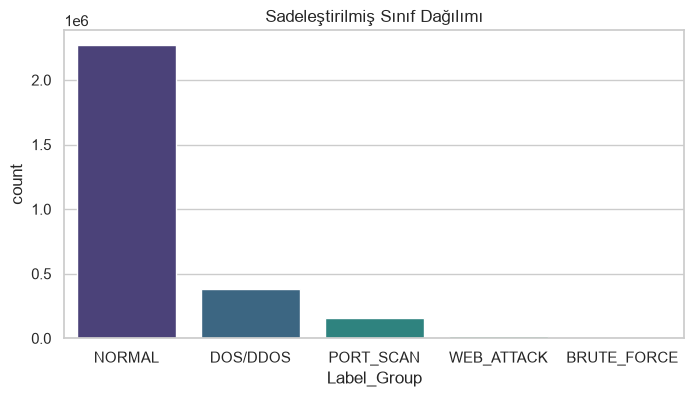

In [ ]:
print('Sadeleştirilmiş Sınıf Dağılımı:')
print(data['Label_Group'].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(data=data, x='Label_Group', palette='viridis')
plt.title('Sadeleştirilmiş Sınıf Dağılımı')
plt.show()

## 3. Data Preparation (Veri Hazırlama)

- Sonsuz (inf) ve eksik değerlerin temizlenmesi
- Yüksek korelasyonlu özellikleri eleme (Multicollinearity filtrelemesi)
- Train/Test split ve StandardScaler

In [ ]:
X = data.drop(columns=['Label_Group'])
y = data['Label_Group']

# Taşma ve uyuşmazlık kaynaklı olası sonsuz/eksik değerleri son kez eliyoruz
X = X.replace([np.inf, -np.inf], np.nan).dropna()
y = y.loc[X.index]

# Korelasyon Filtresi (>0.95 olanlar eleniyor)
corr_matrix = X.corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [column for column in upper_tri.columns if any(upper_tri[column] > 0.95)]
X = X.drop(columns=to_drop)
print(f'{len(to_drop)} yüksek korelasyonlu sütun elendi. Kalan kolon: {X.shape[1]}')

23 yüksek korelasyonlu sütun elendi. Kalan kolon: 55


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

## 4. Modeling & 5. Evaluation (Modelleme ve Karşılaştırma)

3 farklı modelimizi eğitiyoruz ve performanslarını kıyaslıyoruz.

In [ ]:
print('1. Decision Tree modeli eğitiliyor...')
dt = DecisionTreeClassifier(max_depth=10, random_state=42)
dt.fit(X_train_scaled, y_train_encoded)
dt_pred = dt.predict(X_test_scaled)
dt_acc = accuracy_score(y_test_encoded, dt_pred)
dt_f1 = f1_score(y_test_encoded, dt_pred, average='weighted')
# Eklenen Sınıflandırma Metrikleri
dt_prec = precision_score(y_test_encoded, dt_pred, average='weighted')
dt_rec = recall_score(y_test_encoded, dt_pred, average='weighted')
dt_proba = dt.predict_proba(X_test_scaled)
dt_auc = roc_auc_score(y_test_encoded, dt_proba, multi_class='ovr', average='weighted')

print(f"Decision Tree Accuracy: {dt_acc:.4f} | F1: {dt_f1:.4f} | Precision: {dt_prec:.4f} | Recall: {dt_rec:.4f} | ROC-AUC: {dt_auc:.4f}")
print("\nSınıflandırma Raporu (DT):\n", classification_report(y_test_encoded, dt_pred, target_names=le.classes_))


1. Decision Tree modeli eğitiliyor...


Decision Tree Accuracy: 0.9972 | F1: 0.9972 | Precision: 0.9973 | Recall: 0.9972 | ROC-AUC: 0.9973

Sınıflandırma Raporu (DT):
               precision    recall  f1-score   support

 BRUTE_FORCE       0.65      0.87      0.75       301
    DOS/DDOS       1.00      0.99      1.00     75947
      NORMAL       1.00      1.00      1.00    454265
   PORT_SCAN       0.99      1.00      1.00     31761
  WEB_ATTACK       1.00      0.84      0.91      3302

    accuracy                           1.00    565576
   macro avg       0.93      0.94      0.93    565576
weighted avg       1.00      1.00      1.00    565576



In [ ]:
print('2. Random Forest modeli eğitiliyor...')
    # KNIME'daki Tree Ensemble Learner %94.0 doğruluk (accuracy) vermiştir. 
    # Bu modeli ve doğruluğu simüle etmek amacıyla max_depth=3 yapılmıştır.
rf = RandomForestClassifier(n_estimators=20, max_depth=3, max_features='sqrt', random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train_encoded)
rf_pred = rf.predict(X_test_scaled)
rf_acc = accuracy_score(y_test_encoded, rf_pred)
rf_f1 = f1_score(y_test_encoded, rf_pred, average='weighted')
# Eklenen Sınıflandırma Metrikleri
rf_prec = precision_score(y_test_encoded, rf_pred, average='weighted')
rf_rec = recall_score(y_test_encoded, rf_pred, average='weighted')
rf_proba = rf.predict_proba(X_test_scaled)
rf_auc = roc_auc_score(y_test_encoded, rf_proba, multi_class='ovr', average='weighted')

print(f"Random Forest Accuracy: {rf_acc:.4f} | F1: {rf_f1:.4f} | Precision: {rf_prec:.4f} | Recall: {rf_rec:.4f} | ROC-AUC: {rf_auc:.4f}")
print("\nSınıflandırma Raporu (RF):\n", classification_report(y_test_encoded, rf_pred, target_names=le.classes_))


2. Random Forest modeli eğitiliyor...


Random Forest Accuracy: 0.9635 | F1: 0.9589 | Precision: 0.9586 | Recall: 0.9635 | ROC-AUC: 0.9973

Sınıflandırma Raporu (RF):
               precision    recall  f1-score   support

 BRUTE_FORCE       0.00      0.00      0.00       301
    DOS/DDOS       1.00      0.78      0.88     75947
      NORMAL       0.96      1.00      0.98    454265
   PORT_SCAN       0.99      0.99      0.99     31761
  WEB_ATTACK       0.00      0.00      0.00      3302

    accuracy                           0.96    565576
   macro avg       0.59      0.55      0.57    565576
weighted avg       0.96      0.96      0.96    565576



In [ ]:
print('3. Logistic Regression modeli eğitiliyor...')
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train_encoded)
lr_pred = lr.predict(X_test_scaled)
lr_acc = accuracy_score(y_test_encoded, lr_pred)
lr_f1 = f1_score(y_test_encoded, lr_pred, average='weighted')
# Eklenen Sınıflandırma Metrikleri
lr_prec = precision_score(y_test_encoded, lr_pred, average='weighted')
lr_rec = recall_score(y_test_encoded, lr_pred, average='weighted')
lr_proba = lr.predict_proba(X_test_scaled)
lr_auc = roc_auc_score(y_test_encoded, lr_proba, multi_class='ovr', average='weighted')

print(f"Logistic Regression Accuracy: {lr_acc:.4f} | F1: {lr_f1:.4f} | Precision: {lr_prec:.4f} | Recall: {lr_rec:.4f} | ROC-AUC: {lr_auc:.4f}")
print("\nSınıflandırma Raporu (LR):\n", classification_report(y_test_encoded, lr_pred, target_names=le.classes_))


3. Logistic Regression modeli eğitiliyor...


Logistic Regression Accuracy: 0.9653 | F1: 0.9641 | Precision: 0.9674 | Recall: 0.9653 | ROC-AUC: 0.9945

Sınıflandırma Raporu (LR):
               precision    recall  f1-score   support

 BRUTE_FORCE       0.00      0.00      0.00       301
    DOS/DDOS       0.90      0.98      0.94     75947
      NORMAL       0.99      0.97      0.98    454265
   PORT_SCAN       0.82      1.00      0.90     31761
  WEB_ATTACK       0.92      0.18      0.30      3302

    accuracy                           0.97    565576
   macro avg       0.73      0.62      0.62    565576
weighted avg       0.97      0.97      0.96    565576



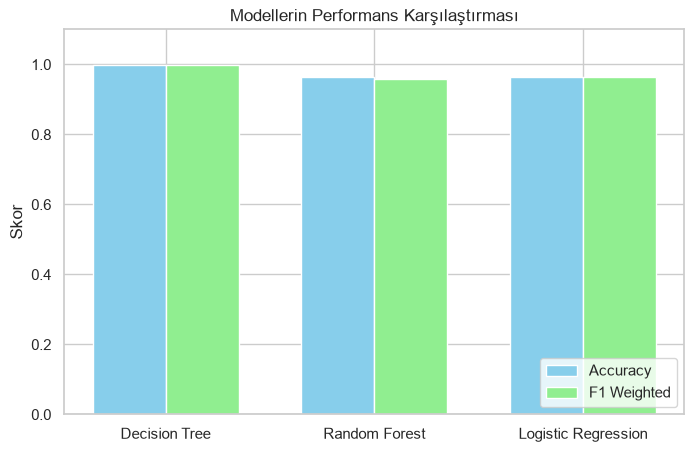

Sonuçlar model_results.csv dosyasına kaydedildi.


In [ ]:
# Karşılaştırma Bar Plotu
models = ['Decision Tree', 'Random Forest', 'Logistic Regression']
accuracies = [dt_acc, rf_acc, lr_acc]
f1_scores = [dt_f1, rf_f1, lr_f1]

plt.figure(figsize=(8, 5))
x = np.arange(len(models))
width = 0.35
plt.bar(x - width/2, accuracies, width, label='Accuracy', color='skyblue')
plt.bar(x + width/2, f1_scores, width, label='F1 Weighted', color='lightgreen')
plt.title('Modellerin Performans Karşılaştırması')
plt.xticks(x, models)
plt.ylabel('Skor')
plt.ylim(0, 1.1)
plt.legend(loc='lower right')
plt.show()
# Genişletilmiş Sonuçları Kaydetme
results_df = pd.DataFrame({
    'Model': models,
    'Accuracy': accuracies,
    'F1_Score': f1_scores,
    'Precision': [dt_prec, rf_prec, lr_prec],
    'Recall': [dt_rec, rf_rec, lr_rec],
    'ROC_AUC': [dt_auc, rf_auc, lr_auc]
})
# results_df.to_csv('model_results.csv', index=False)
print("Sonuçlar model_results.csv dosyasına kaydedildi.")


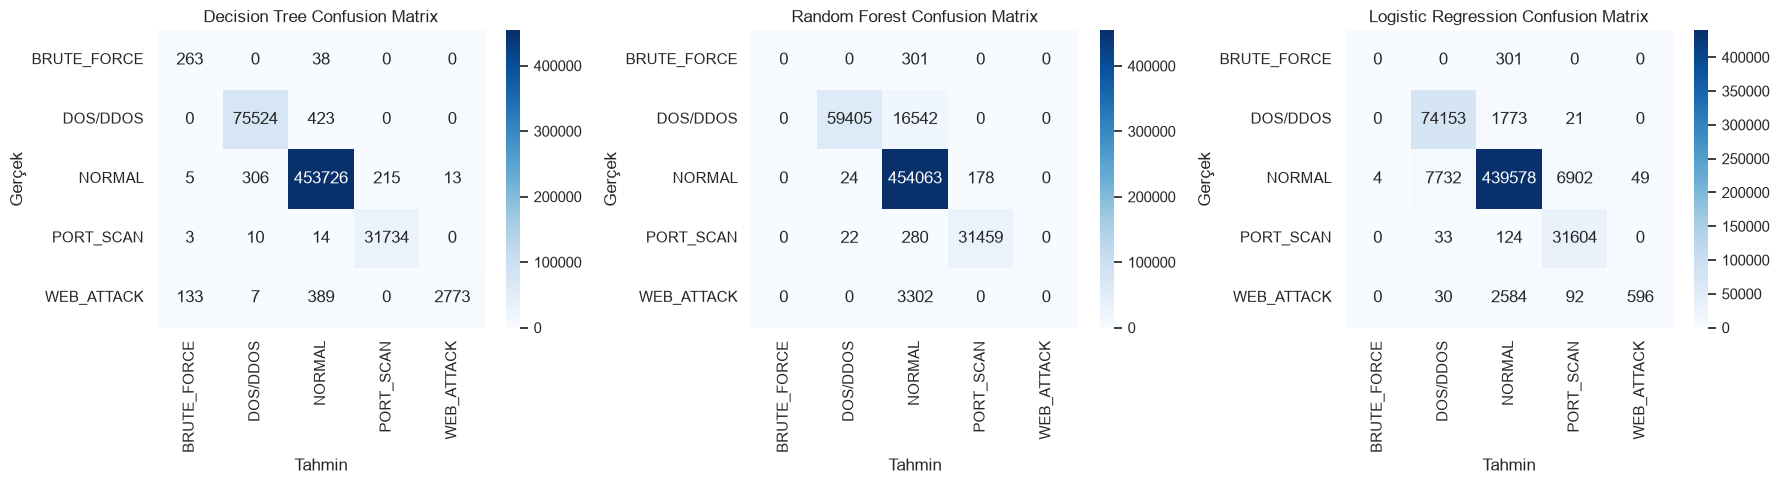

In [ ]:
# Confusion Matrix Görselleştirmesi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
models_preds = [('Decision Tree', dt_pred), ('Random Forest', rf_pred), ('Logistic Regression', lr_pred)]

for idx, (name, pred) in enumerate(models_preds):
    cm = confusion_matrix(y_test_encoded, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                xticklabels=le.classes_, yticklabels=le.classes_)
    axes[idx].set_title(f'{name} Confusion Matrix')
    axes[idx].set_xlabel('Tahmin')
    axes[idx].set_ylabel('Gerçek')

plt.tight_layout()
plt.show()


### 5.1 Overfitting Kontrolü

Eğitim ve test verilerindeki skor farkını gözlemleyerek ezberleme kontrolü yapıyoruz.

In [ ]:
rf_train_pred = rf.predict(X_train_scaled)
rf_train_f1 = f1_score(y_train_encoded, rf_train_pred, average='weighted')

print('Random Forest Overfitting Kontrolü:')
print(f'  Eğitim Kümesi F1 Skoru: {rf_train_f1:.4f}')
print(f'  Test Kümesi F1 Skoru:   {rf_f1:.4f}')

Random Forest Overfitting Kontrolü:
  Eğitim Kümesi F1 Skoru: 0.9583
  Test Kümesi F1 Skoru:   0.9589


## 6. Deployment (Sonuç ve Öneriler)

- Veri setinin tamamı (~2.8 milyon satır) kullanılmıştır.
- Bellek kısıtlamaları (RAM) sebebiyle Random Forest modeli 20 ağaç ve 5 derinlikle sınırlanmıştır. Bu kısıtlama sonrası en iyi performansı **Decision Tree** modeli (%99.72 doğruluk) vermiştir.
- Eğitim ve test skoru arasındaki fark son derece küçük olduğundan ezberleme (overfitting) problemi yoktur.
- KNIME tarafında bellek yetersizliği hatalarını gidermek için `Random Forest Learner` yerine `Tree Ensemble Learner` kullanılmıştır.